
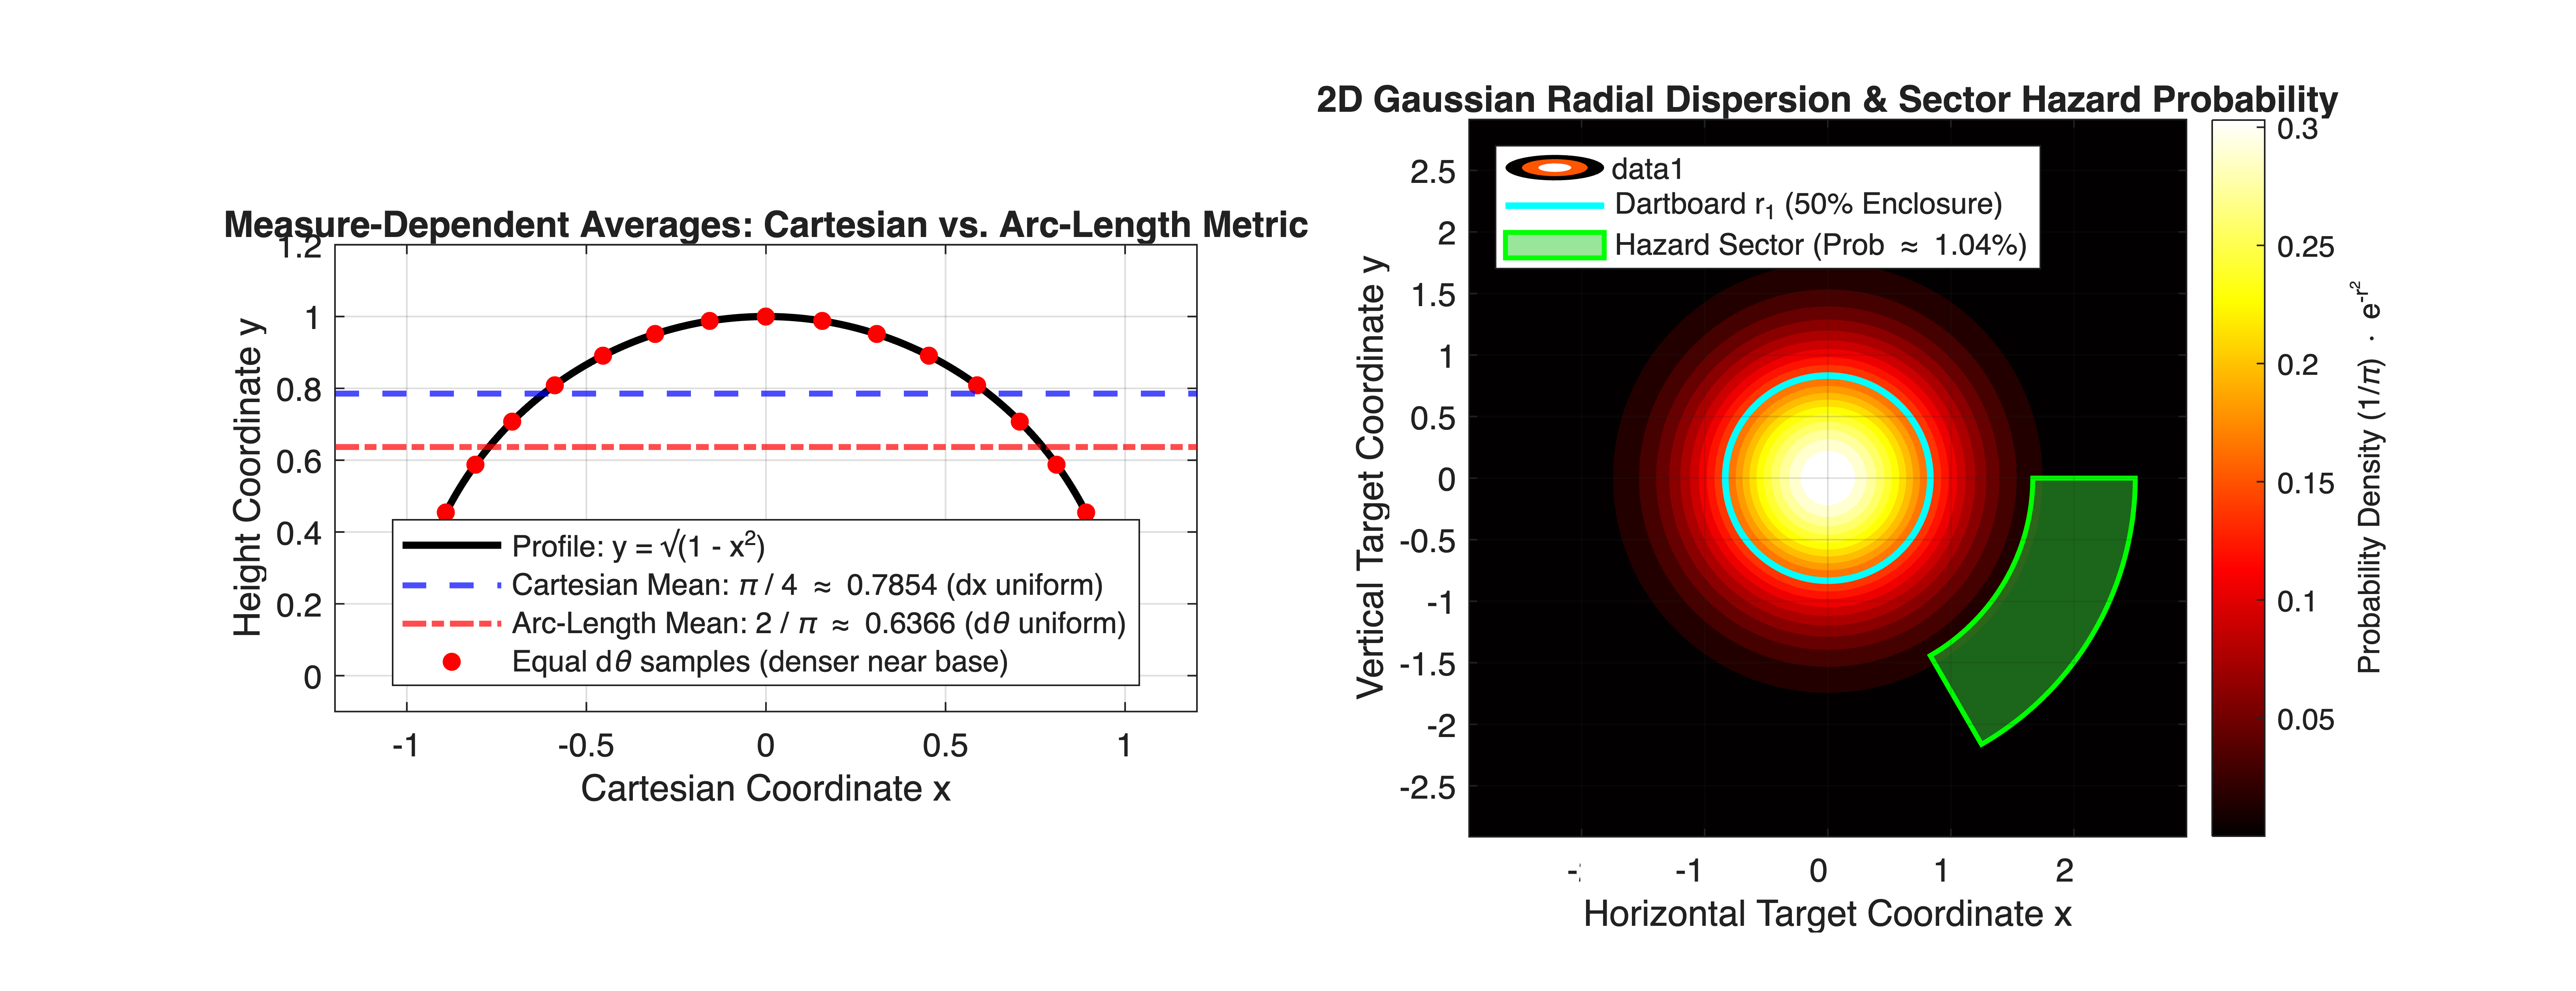

In [1]:
%% MIT 18.01 Lecture 23: Average Value, Gaussian Integration & Probability
% Mathematical Tool Application: Used for stochastic noise covariance calibration
% in Kalman filters, control error RMS metrics, lumped thermal model reduction,
% and 2D circular error probable (CEP) probability dispersion evaluation.


clear; clc; close all;


%% Part 1: Semicircle Average Height: Cartesian vs. Arc-Length Weighting
% Geometry: y = sqrt(1 - x^2) on [-1, 1], or y = sin(theta) on [0, pi]
x_span = linspace(-1.0, 1.0, 400);
y_semicircle = sqrt(max(0, 1.0 - x_span.^2));


% Analytical Mean Heights derived in Lecture 23:
% 1. Uniform weighting in x:      y_avg_x = (1 / 2) * \int_{-1}^1 sqrt(1-x^2) dx = pi / 4
% 2. Uniform weighting in theta:  y_avg_theta = (1 / pi) * \int_0^pi sin(theta) dtheta = 2 / pi
y_mean_cartesian = pi / 4.0; % approx 0.7854
y_mean_arclength = 2.0 / pi; % approx 0.6366


figure('Color', 'w', 'Position', [100, 100, 1250, 480]);


subplot(1, 2, 1);
plot(x_span, y_semicircle, 'k-', 'LineWidth', 2.2, 'DisplayName', 'Profile: y = \surd(1 - x^2)'); hold on;


% Plot horizontal average lines
yline(y_mean_cartesian, 'b--', 'LineWidth', 1.8, ...
    'DisplayName', sprintf('Cartesian Mean: \\pi / 4 \\approx %.4f (dx uniform)', y_mean_cartesian));
yline(y_mean_arclength, 'r-.', 'LineWidth', 1.8, ...
    'DisplayName', sprintf('Arc-Length Mean: 2 / \\pi \\approx %.4f (d\\theta uniform)', y_mean_arclength));


% Highlight discrete point density difference
theta_samples = linspace(0, pi, 21);
x_theta_pts = cos(theta_samples);
y_theta_pts = sin(theta_samples);
plot(x_theta_pts, y_theta_pts, 'ro', 'MarkerSize', 5, 'MarkerFaceColor', 'r', ...
    'DisplayName', 'Equal d\theta samples (denser near base)');


grid on; axis equal;
xlim([-1.2, 1.2]); ylim([-0.1, 1.2]);
xlabel('Cartesian Coordinate x');
ylabel('Height Coordinate y');
title('Measure-Dependent Averages: Cartesian vs. Arc-Length Metric');
legend('Location', 'south');


%% Part 2: 2D Gaussian Radial Target Probability Field (Dartboard Problem)
subplot(1, 2, 2);


% Radial calibration from lecture: P(0 <= r <= r1) = 0.5 => exp(-r1^2) = 0.5
r1_dartboard = sqrt(log(2.0)); % approx 0.8326


% 2D Grid for Gaussian surface: p(x, y) = (1 / pi) * exp(-(x^2 + y^2))
grid_limit = 3.5 * r1_dartboard;
[X_grid, Y_grid] = meshgrid(linspace(-grid_limit, grid_limit, 200));
R_grid = sqrt(X_grid.^2 + Y_grid.^2);
PDF_2D = (1.0 / pi) * exp(-R_grid.^2);


% Plot probability contours
contourf(X_grid, Y_grid, PDF_2D, 20, 'LineColor', 'none'); hold on;
colormap('hot');
cbar = colorbar;
cbar.Label.String = 'Probability Density (1/\pi) \cdot e^{-r^2}';


% Draw 50% hit target dartboard circle (r = r1)
theta_circle = linspace(0, 2*pi, 300);
plot(r1_dartboard * cos(theta_circle), r1_dartboard * sin(theta_circle), ...
    'c-', 'LineWidth', 2.0, 'DisplayName', sprintf('Dartboard r_1 (50%% Enclosure)'));


% Draw Hazard Sector: 2*r1 < r < 3*r1 between 3 o''clock and 5 o''clock
% 3 o'clock is 0 rad, 5 o'clock is -pi/3 rad (-60 deg)
theta_sector = linspace(-pi/3, 0, 50);
r_inner = 2.0 * r1_dartboard;
r_outer = 3.0 * r1_dartboard;


x_sec_poly = [r_inner * cos(theta_sector), fliplr(r_outer * cos(theta_sector))];
y_sec_poly = [r_inner * sin(theta_sector), fliplr(r_outer * sin(theta_sector))];
patch(x_sec_poly, y_sec_poly, [0.2, 0.8, 0.2], 'FaceAlpha', 0.5, 'EdgeColor', 'g', ...
    'LineWidth', 1.5, 'DisplayName', 'Hazard Sector (Prob \approx 1.04%)');


grid on; axis equal;
xlim([-grid_limit, grid_limit]); ylim([-grid_limit, grid_limit]);
xlabel('Horizontal Target Coordinate x');
ylabel('Vertical Target Coordinate y');
title('2D Gaussian Radial Dispersion & Sector Hazard Probability');
legend('Location', 'northwest');

In [2]:


%% Numerical Proof of Gaussian Normalization Q = sqrt(pi)
Q_numerical = integral(@(x) exp(-x.^2), -Inf, Inf, 'RelTol', 1e-12, 'AbsTol', 1e-14);
fprintf('Gaussian Integral Verification: Q = %.10f (Theoretical \\surd\\pi = %.10f)\n', ...
    Q_numerical, sqrt(pi));

Gaussian Integral Verification: Q = 1.7724538509 (Theoretical \surd\pi = 1.7724538509)